# Online Shopper Conversion Prediction

## 1. Modeling Objective

The goal of this analysis is to predict whether an online shopping session will result in a purchase using the Online Shoppers Purchasing Intention dataset.

Several classification models will be trained and compared to identify a model that can distinguish purchasing sessions from non-purchasing sessions. Model evaluation will emphasize precision, recall, F1-score, ROC-AUC, and the confusion matrix because the target classes are imbalanced.

The training set will be used to fit models, the validation set will support model comparison and hyperparameter tuning, and the test set will be reserved for final evaluation.

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [3]:
# load datasets, adjust path as needed
possible_paths = [
    Path("data/online_shoppers_intention.csv"),
    Path(r"C:\Users\tlsun\OneDrive\Desktop\USD Assignment\Applied Data Science for Business\Final Project 505\online_shoppers_intention.csv"),
    Path.home() / "Downloads" / "online_shoppers_intention.csv",
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None,
)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find online_shoppers_intention.csv. "
        "Place it in the project's data folder or your Downloads folder."
    )

df = pd.read_csv(csv_path)

print(f"Loaded dataset from: {csv_path.resolve()}")
print(f"Dataset shape: {df.shape}")
display(df.head())

Loaded dataset from: C:\Users\tlsun\OneDrive\Desktop\USD Assignment\Applied Data Science for Business\Final Project 505\online_shoppers_intention.csv
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("Target distribution:")
display(
    df["Revenue"]
    .value_counts()
    .rename(index={False: "No Purchase", True: "Purchase"})
    .to_frame("Count")
)

print("\nTarget proportions:")
display(
    (
        df["Revenue"]
        .value_counts(normalize=True)
        .mul(100)
        .rename(index={False: "No Purchase", True: "Purchase"})
        .to_frame("Percentage")
        .round(2)
    )
)

Target distribution:


,Count
Revenue,
No Purchase,10422
Purchase,1908



Target proportions:


,Percentage
Revenue,
No Purchase,84.53
Purchase,15.47



## 2. Feature Engineering and Preprocessing

Three engagement features are created from the original session variables: total pages visited, total session duration, and average duration per page. The data is split into training, validation, and test sets using stratified sampling to preserve the purchase rate.

Numerical features are imputed and standardized, while categorical features are imputed and one-hot encoded. Preprocessing is fitted only on the training set to reduce data leakage.


In [5]:
# Create engineered features and define the target
# Create a working copy
model_df = df.copy()

# Engineer engagement features
model_df["TotalPages"] = (
    model_df["Administrative"]
    + model_df["Informational"]
    + model_df["ProductRelated"]
)

model_df["TotalDuration"] = (
    model_df["Administrative_Duration"]
    + model_df["Informational_Duration"]
    + model_df["ProductRelated_Duration"]
)

model_df["AvgDurationPerPage"] = (
    model_df["TotalDuration"]
    / model_df["TotalPages"].replace(0, 1)
)

# Define target and predictors
X = model_df.drop(columns="Revenue")
y = model_df["Revenue"].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nEngineered features:")
display(
    model_df[
        ["TotalPages", "TotalDuration", "AvgDurationPerPage"]
    ].describe().round(2)
)

Feature matrix shape: (12330, 20)
Target shape: (12330,)

Engineered features:


,TotalPages,TotalDuration,AvgDurationPerPage
count,12330.00,12330.00,12330.00
mean,34.55,1310.04,37.79
std,46.51,2037.80,43.42
min,0.00,0.00,0.00
25%,8.00,222.00,18.23
50%,20.00,680.00,29.69
75%,42.00,1626.91,45.42
max,746.00,69921.65,1411.00


In [6]:
# Split into training, validation, and test sets
from sklearn.model_selection import train_test_split

# First, set aside 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Split the remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1765,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

print("Training set:", X_train.shape, f"({len(X_train) / len(X):.1%})")
print("Validation set:", X_val.shape, f"({len(X_val) / len(X):.1%})")
print("Test set:", X_test.shape, f"({len(X_test) / len(X):.1%})")

print("\nPurchase rate by split:")
print(f"Training:   {y_train.mean():.2%}")
print(f"Validation: {y_val.mean():.2%}")
print(f"Test:       {y_test.mean():.2%}")


Training set: (8630, 20) (70.0%)
Validation set: (1850, 20) (15.0%)
Test set: (1850, 20) (15.0%)

Purchase rate by split:
Training:   15.48%
Validation: 15.46%
Test:       15.46%


In [7]:
# Define preprocessing

# Numerical features
numeric_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "TotalPages",
    "TotalDuration",
    "AvgDurationPerPage",
]

# Categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]

# Preprocess numerical and categorical variables separately
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Fit only on training data
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)

print("Processed training shape:", X_train_prep.shape)
print("Processed validation shape:", X_val_prep.shape)
print("Processed test shape:", X_test_prep.shape)


Processed training shape: (8630, 77)
Processed validation shape: (1850, 77)
Processed test shape: (1850, 77)


In [8]:
# Verify the prepared data
print("Missing values in original predictors:", X.isna().sum().sum())
print("Training target classes:", np.bincount(y_train))
print("Validation target classes:", np.bincount(y_val))
print("Test target classes:", np.bincount(y_test))

assert X_train_prep.shape[0] == len(y_train)
assert X_val_prep.shape[0] == len(y_val)
assert X_test_prep.shape[0] == len(y_test)

print("\nPreprocessing completed successfully.")

Missing values in original predictors: 0
Training target classes: [7294 1336]
Validation target classes: [1564  286]
Test target classes: [1564  286]

Preprocessing completed successfully.


## 3. Model Training and Comparison

Four classification models are evaluated using the training and validation sets. Performance is compared using accuracy, precision, recall, F1-score, and ROC-AUC. Since purchase sessions represent a minority of observations, particular attention is given to identifying actual purchase sessions rather than maximizing accuracy alone.


In [10]:
# Convert sparse matrices to dense arrays if needed
if hasattr(X_train_prep, "toarray"):
    X_train_prep = X_train_prep.toarray()
    X_val_prep = X_val_prep.toarray()
    X_test_prep = X_test_prep.toarray()

print("Training data shape:", X_train_prep.shape)
print("Data type:", type(X_train_prep))


# Train the model
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
}

validation_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_prep, y_train)

    y_pred = model.predict(X_val_prep)
    y_prob = model.predict_proba(X_val_prep)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
    })

    trained_models[name] = model

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(validation_results_df.round(4))


Training data shape: (8630, 77)
Data type: <class 'numpy.ndarray'>


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting,0.8941,0.7143,0.5245,0.6048,0.9263
1,Random Forest,0.8968,0.7844,0.4580,0.5784,0.9165
2,Decision Tree,0.8611,0.5495,0.5629,0.5561,0.7393
3,Logistic Regression,0.8822,0.7361,0.3706,0.4930,0.8903


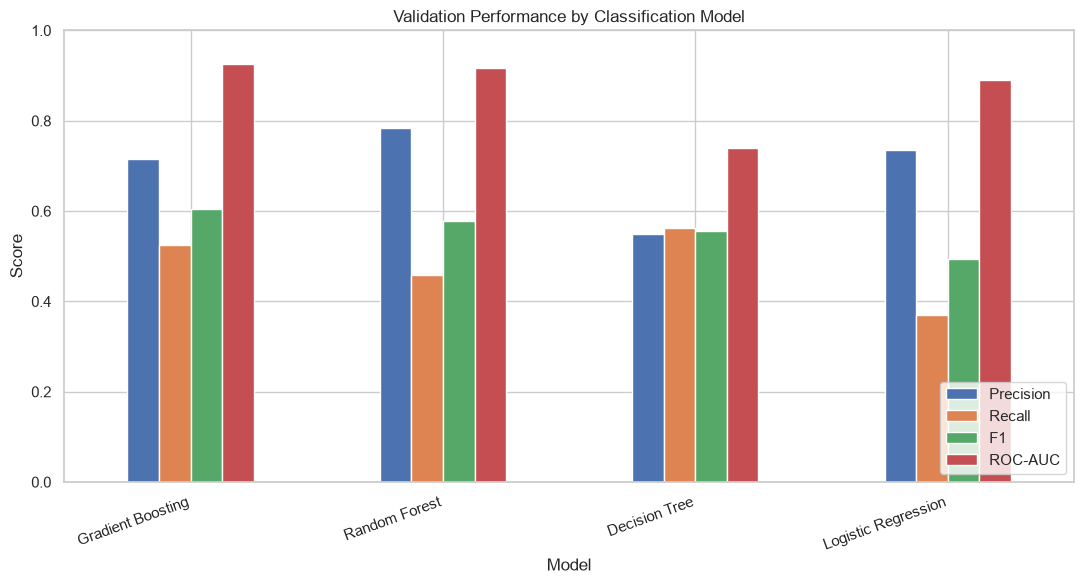

In [11]:
# Visualize the comparison

metrics_to_plot = ["Precision", "Recall", "F1", "ROC-AUC"]

validation_results_df.set_index("Model")[
    metrics_to_plot
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1))

plt.title("Validation Performance by Classification Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Hyperparameter Tuning/ Gradient Boosting

Gradient Boosting achieved the best validation F1 score and ROC-AUC in the initial model comparison. Grid search will be used to evaluate different hyperparameter combinations and identify a model that improves the balance between precision and recall. The test set will remain untouched until final model evaluation.

In [12]:
from sklearn.model_selection import GridSearchCV

gb_model = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE
)

param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31],
    "l2_regularization": [0.0, 1.0],
}

grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train_prep, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15}
Best cross-validation F1: 0.6772


In [13]:
#Tune Gradient Boosting
param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31],
}

grid_search = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
)

grid_search.fit(X_train_prep, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Best parameters: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 15}
Best cross-validation F1: 0.6753


In [14]:
best_model = grid_search.best_estimator_

y_val_pred = best_model.predict(X_val_prep)
y_val_prob = best_model.predict_proba(X_val_prep)[:, 1]

print("Validation Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Validation Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation F1:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

Validation Accuracy: 0.9027
Validation Precision: 0.7524
Validation Recall: 0.5524
Validation F1: 0.6371
Validation ROC-AUC: 0.9332


## 5. Final Test Set Evaluation

The tuned Gradient Boosting model is evaluated on the held-out test set to estimate its performance on unseen data. The test set was not used for model training or hyperparameter tuning.

In [15]:
best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test_prep)
y_test_prob = best_model.predict_proba(X_test_prep)[:, 1]

test_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
}])

display(test_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.9022,0.7215,0.5979,0.6539,0.936


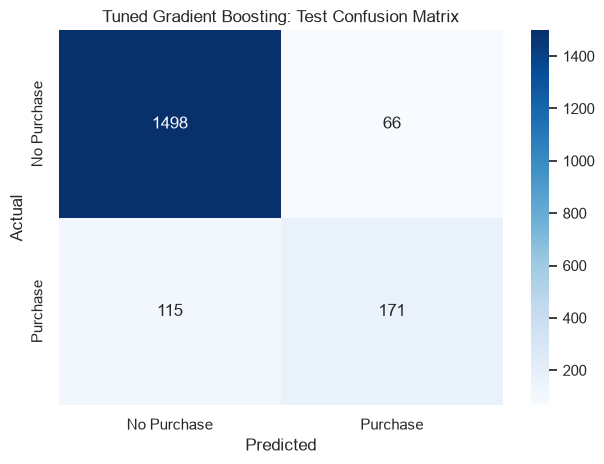

              precision    recall  f1-score   support

 No Purchase       0.93      0.96      0.94      1564
    Purchase       0.72      0.60      0.65       286

    accuracy                           0.90      1850
   macro avg       0.83      0.78      0.80      1850
weighted avg       0.90      0.90      0.90      1850



In [16]:
# Confusion matrix and classification report
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"],
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Gradient Boosting: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0,
))

The tuned Gradient Boosting model achieved 90.22% accuracy, 72.15% precision, 59.79% recall, an F1 score of 0.6539, and a ROC-AUC of 0.9360 on the test set. The model correctly identified 60% of actual purchasing sessions, while approximately 72% of its predicted purchases were correct. Performance was stronger for non-purchasing sessions, with 96% recall, reflecting the imbalance in the dataset. The results suggest that the model can help identify potential purchasers, although it still misses some sessions that result in purchases.

## 6. Feature Importance

,Feature,Importance
8,num__PageValues,0.4636
7,num__ExitRates,0.0482
20,cat__Month_Nov,0.0455
1,num__Administrative_Duration,0.0132
0,num__Administrative,0.0121
10,num__TotalPages,0.0117
19,cat__Month_May,0.0079
4,num__ProductRelated,0.0072
52,cat__Region_9,0.0072
14,cat__Month_Dec,0.0071


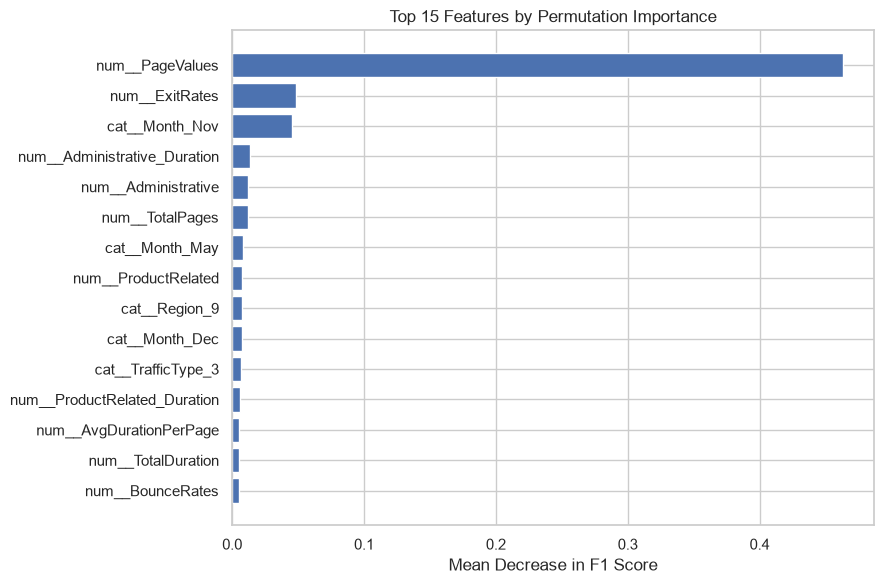

In [17]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_val_prep,
    y_val,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance.importances_mean,
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Mean Decrease in F1 Score")
plt.title("Top 15 Features by Permutation Importance")
plt.tight_layout()
plt.show()

Permutation importance identified PageValues as the most influential feature, with an importance score of 0.4636, substantially higher than the other features. ExitRates was the second most important feature at 0.0482, followed by the November indicator at 0.0455. Administrative activity, total pages viewed, and product-related activity also contributed to model performance, although their individual importance scores were much smaller.

These results suggest that page-value information and browsing behavior are particularly useful for predicting whether a session results in a purchase. However, feature importance indicates predictive usefulness, not causation. The strong importance of PageValues should also be interpreted in the context of how this variable is defined in the dataset.